In [26]:
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
from pyproj import Transformer
%matplotlib widget

In [27]:
ds = xr.open_dataset('output/shoreline_model_output.nc')
lrr = pd.read_csv('/hpc/dctrl/acd99/stuff_for_dylan/coastsat_lrr_obx_1984_2025.csv').set_index('transect_id')

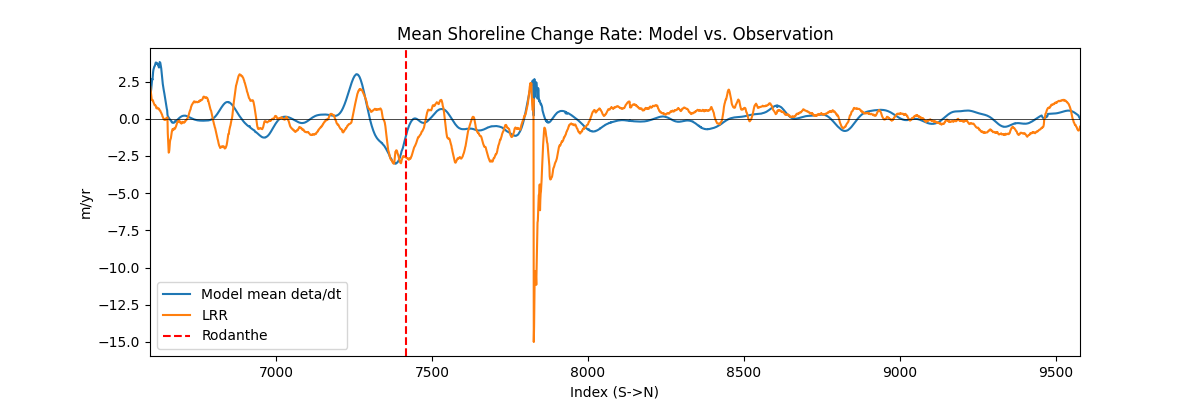

In [28]:
years = (ds['time'][-1] - ds['time'][0]).values / np.timedelta64(1, 'D') / 365.25
model_rate = (ds['eta'].isel(time=-1) - ds['eta'].isel(time=0)) / years
obs_rate = lrr['lrr_m_yr'].reindex(ds['site'].values)
rodanthe_site = 'usa_NC_0036_0027'
rodanthe_idx = np.where(ds['site'].values == rodanthe_site)[0][0]
both = np.isfinite(model_rate.values) & np.isfinite(obs_rate.values)
idx = np.arange(len(both))[both]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(idx, model_rate.values[both], label='Model mean deta/dt')
ax.plot(idx, obs_rate.values[both], label='LRR')
ax.axvline(x=rodanthe_idx, color='r', linestyle='--', label='Rodanthe')
ax.axhline(0, color='k', lw=0.5)
ax.set_xlim(idx[0], idx[-1])
ax.set_xlabel('Index (S->N)')
ax.set_ylabel('m/yr')
ax.set_title('Mean Shoreline Change Rate: Model vs. Observation')
ax.legend()
plt.show()

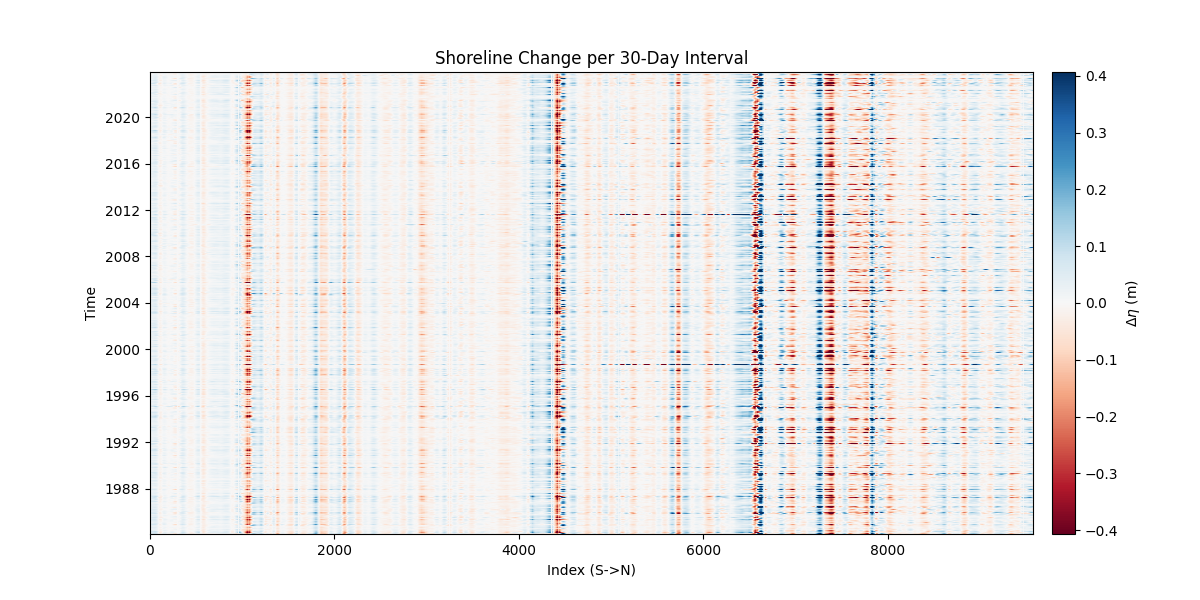

In [29]:
ds = xr.open_dataset('output/shoreline_model_output.nc')

t_start, t_end = None, None   # optional time window, e.g. '2000-01-01', '2002-01-01' (None = whole run)

eta = ds['eta'].sel(time=slice(t_start, t_end))
d_eta = eta.diff('time')      # eta(t) - eta(previous record)
step_days = float(np.median(np.diff(eta['time'].values)) / np.timedelta64(1, 'D'))

vals = d_eta.values
lim = np.nanpercentile(np.abs(vals), 99.5)
t = mdates.date2num(d_eta['time'].values)

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(vals, aspect='auto', origin='lower', cmap='RdBu', vmin=-lim, vmax=lim,
               interpolation='nearest', extent=[0, vals.shape[1], t[0], t[-1]])
ax.yaxis_date()
ax.set_xlabel('Index (S->N)')
ax.set_ylabel('Time')
ax.set_title(f'Shoreline Change per {step_days:g}-Day Interval')
plt.colorbar(im, ax=ax, label=r'$\Delta \eta$ (m)', fraction=0.03, pad=0.02)
plt.show()

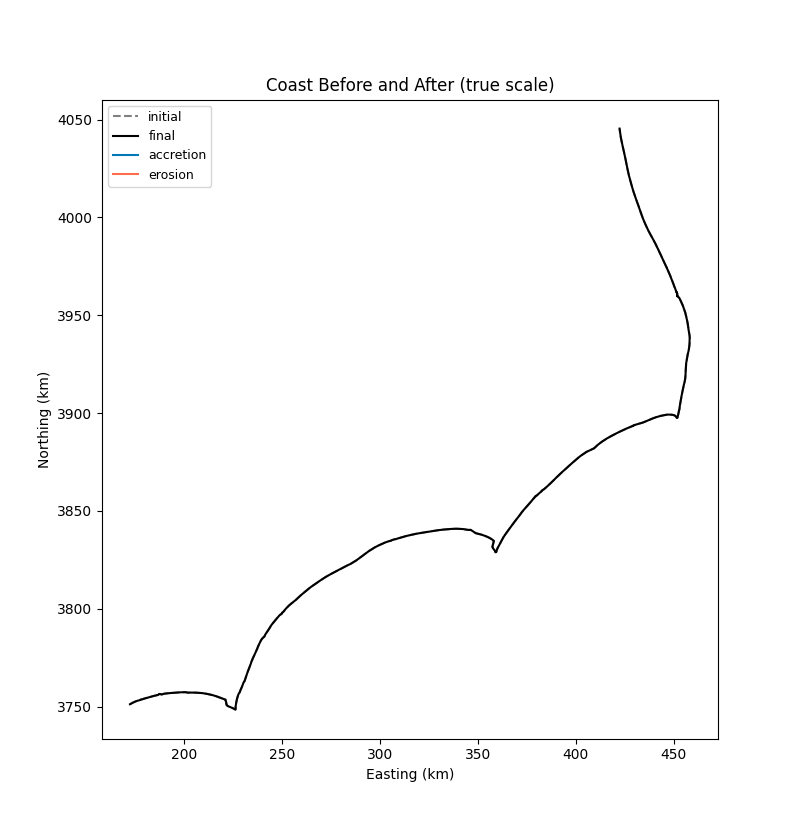

In [30]:
# initial and final shorelines in UTM 18N (meters), the same CRS the model uses
to_utm = Transformer.from_crs('EPSG:4326', 'EPSG:32618', always_xy=True)
x0, y0 = to_utm.transform(ds['shore_lon'].isel(time=0).values, ds['shore_lat'].isel(time=0).values)
x1, y1 = to_utm.transform(ds['shore_lon'].isel(time=-1).values, ds['shore_lat'].isel(time=-1).values)
x0, y0, x1, y1 = (np.asarray(a) / 1e3 for a in (x0, y0, x1, y1))   # km
net = (ds['eta'].isel(time=-1) - ds['eta'].isel(time=0)).values

ok = np.isfinite(x1) & np.isfinite(y1)   # sites omitted by the model are NaN at the end

# one short segment per site, from its initial to its final position along its transect
segs = np.stack([np.c_[x0[ok], y0[ok]], np.c_[x1[ok], y1[ok]]], axis=1)
colors = np.where(net[ok] >= 0, '#0077B6', '#FE6D4E')

# figure sized to the coast so both axes are at the same scale
w = np.nanmax(x0) - np.nanmin(x0)
h = np.nanmax(y0) - np.nanmin(y0)
fig, ax = plt.subplots(figsize=(8, 8 * h / w))

ax.add_collection(LineCollection(segs, colors=colors, lw=1, alpha=0.6))
ax.plot(x0, y0, color='0.5', ls='--', lw=1.5, label='initial')
ax.plot(x1, y1, color='k', lw=1.5, label='final')
ax.plot([], [], color='#0077B6', label='accretion')
ax.plot([], [], color='#FE6D4E', label='erosion')
ax.set_aspect('equal')
ax.autoscale_view()
ax.ticklabel_format(useOffset=False)
ax.set_xlabel('Easting (km)')
ax.set_ylabel('Northing (km)')
ax.set_title('Coast Before and After (true scale)')
ax.legend(loc='best', fontsize=9)
plt.show()